In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor

#define path
DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"
FIGURES_DIR = Path("../figures")
RESULTS_DIR = Path("../results")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(PROCESSED_DIR / "merged_dataset.csv")

#define variables
target = "daly_rate"
predictors = [
    "gdp_per_capita",
    "oop_expenditure",
    "health_expenditure_per_capita",
    "urban_population"
]
X = df[predictors]
y = df[target]

In [2]:
#train final RF model; keep the parameters identical to in the 04 notebook!!
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X, y)
print("Random Forest model fitted on the full dataset!")

Random Forest model fitted on the full dataset!


In [ ]:
#initialize shap explainer
explainer = shap.TreeExplainer(
    rf_model,
    feature_perturbation="tree_path_dependent"
)
shap_values = explainer(X)
print("SHAP values calculated successfully!")

#check: expect to see 110 observations and 4 predictors
shap_array = shap_values.values
print("SHAP values shape:", shap_array.shape)
print("Dataset shape:", X.shape)

SHAP values calculated successfully!
SHAP values shape: (110, 4)
Dataset shape: (110, 4)


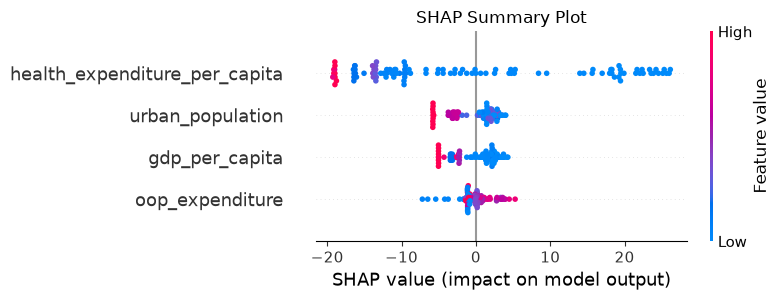

In [5]:
#beeswarm plot
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(
    shap_values,
    show=False
)
plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "shap_summary_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [6]:
#calculate glb shap importance
shap_importance = pd.DataFrame({
    "Feature": predictors,
    "Mean_Absolute_SHAP": np.abs(shap_array).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance

,Feature,Mean_Absolute_SHAP
0,health_expenditure_per_capita,13.373246
1,urban_population,2.526409
2,gdp_per_capita,2.408409
3,oop_expenditure,1.306187


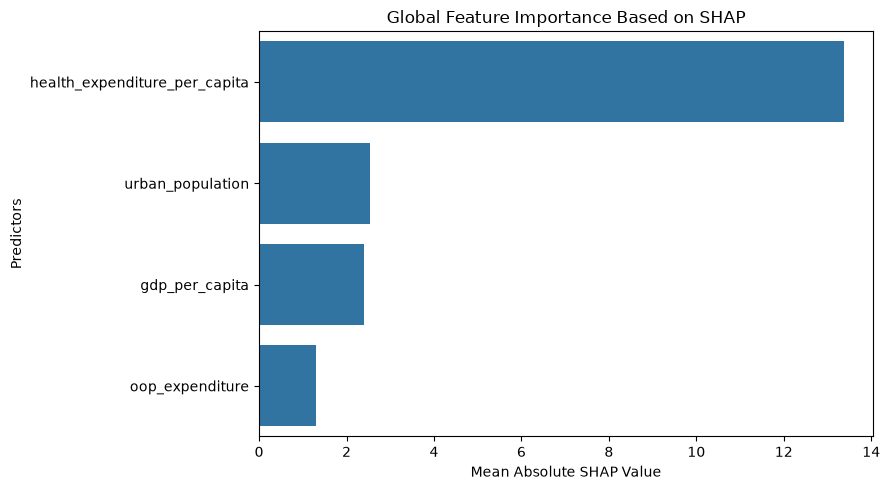

In [7]:
#importance plot
plt.figure(figsize=(9, 5))
sns.barplot(
    data=shap_importance,
    x="Mean_Absolute_SHAP",
    y="Feature"
)
plt.title("Global Feature Importance Based on SHAP")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Predictors")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
#export result
shap_importance.to_csv(
    RESULTS_DIR / "shap_global_importance.csv",
    index=False
)

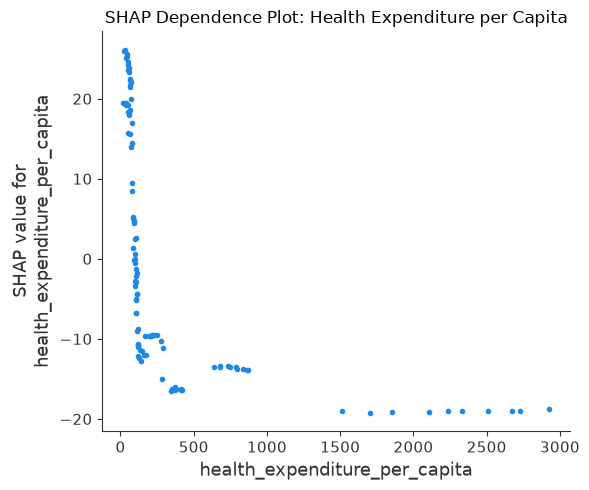

In [9]:
#dependence plot for the most important predictor: health expenditure per capita
shap.dependence_plot(
    "health_expenditure_per_capita",
    shap_array,
    X,
    interaction_index=None,
    show=False
)
plt.title(
    "SHAP Dependence Plot: Health Expenditure per Capita"
)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "shap_health_expenditure_dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
#country-level shap
shap_country = pd.DataFrame(
    np.abs(shap_array),
    columns=predictors
)
shap_country["country"] = df["country"].values
country_shap_summary = (
    shap_country
    .groupby("country")[predictors]
    .mean()
    .reset_index()
)

country_shap_summary

,country,gdp_per_capita,oop_expenditure,health_expenditure_per_capita,urban_population
0,Brunei Darussalam,2.353256,0.945248,13.602721,2.593039
1,Cambodia,2.068829,2.146242,16.912716,2.171023
2,Indonesia,2.765505,0.378451,3.017014,2.267803
3,Lao People's Democratic Republic,1.442062,3.407416,24.675704,1.513935
4,Malaysia,3.316873,0.104537,16.186664,3.308625
5,Myanmar,2.357481,0.870528,18.819871,1.228718
6,Philippines,1.071970,0.996351,8.341348,1.539938
7,Singapore,4.954838,0.294093,19.004930,5.769227
8,Thailand,2.190325,1.082692,9.811263,2.363323
9,Timor-Leste,2.734711,3.416682,8.287049,2.727718


In [11]:
#shap for vn
vietnam_shap = country_shap_summary[
    country_shap_summary["country"] == "Viet Nam"
]
vietnam_shap

country_shap_summary.to_csv(
    RESULTS_DIR / "shap_country_summary.csv",
    index=False
)

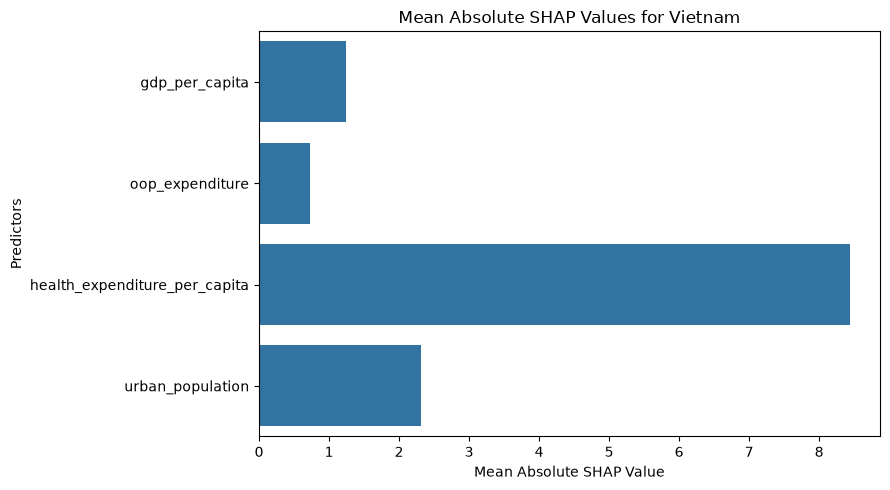

In [12]:
#visualize for vn shap
vietnam_plot = vietnam_shap.melt(
    id_vars="country",
    value_vars=predictors,
    var_name="Feature",
    value_name="Mean_Absolute_SHAP"
)
plt.figure(figsize=(9, 5))
sns.barplot(
    data=vietnam_plot,
    x="Mean_Absolute_SHAP",
    y="Feature"
)
plt.title("Mean Absolute SHAP Values for Vietnam")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Predictors")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "shap_vietnam_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
#export shap value
shap_results = pd.DataFrame(
    shap_array,
    columns=[f"SHAP_{feature}" for feature in predictors]
)
shap_results.insert(0, "year", df["year"].values)
shap_results.insert(0, "country", df["country"].values)
shap_results["daly_rate"] = y.values
shap_results.to_csv(
    RESULTS_DIR / "shap_values.csv",
    index=False
)

print("SHAP results exported successfully!")

SHAP results exported successfully!
